# Lecture 12: Superconducting Qubits and System Engineering

[Course contents](../00_course_contents.md) | [← Previous lecture](./11_quantum_computer_architectures.ipynb) | [Next: supplementary lecture →](./13_quantum_technology_roadmaps_and_ai.ipynb)

> **Open course material.** You may download, teach, adapt, and share this notebook with attribution. It can serve a course at any institution, independent study, exam review, or preparation for work in quantum technology. See the [reuse terms](../LICENSE), the [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and the [citation metadata](../CITATION.cff).

## Learning objectives

- Derive how Josephson nonlinearity turns an LC oscillator into an addressable transmon.
- Relate microwave pulse controls, two-qubit interactions, and dispersive measurement to effective Hamiltonians.
- Build an error budget that separates relaxation, dephasing, leakage, crosstalk, readout, and drift.
- Distinguish physical-device progress from logical error suppression and fault-tolerant application resources.

## Core ideas

- Josephson nonlinearity turns a circuit into an artificial atom, and the microwave, cryogenic, packaging, and calibration stack around it turns that atom into a processor.
- The control and readout Hamiltonians are approximations that hold only in stated regimes, so detuning, anharmonicity, photon number, bandwidth, and leakage have to be engineered together.
- The progress of a whole system is measured at the logical level: device coherence and gate fidelity matter through the complete error budget and the error-correction architecture.


[Watch the recorded lecture on superconducting qubits](https://www.youtube.com/watch?v=sWBDtK175PE).

## Complexity: what a quantum speedup means

- **P** contains decision problems solvable by a deterministic classical algorithm in polynomial time.
- **NP** contains decision problems whose yes-instances have certificates verifiable in polynomial time. NP does not mean “non-polynomial.”
- **BQP** contains decision problems solvable by a quantum algorithm in polynomial time with bounded error.

No known quantum algorithm efficiently solves every NP-complete problem. Shor's algorithm gives polynomial-time quantum algorithms for factoring and discrete logarithms; factoring is not known to be NP-complete. Grover search gives a quadratic, not exponential, reduction in the number of queries for unstructured search.

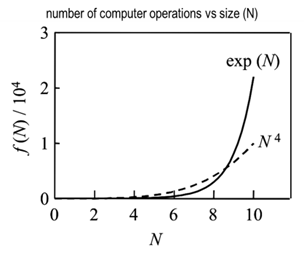

References: E. Bernstein and U. Vazirani, [quantum complexity theory](https://doi.org/10.1137/S0097539796300921); P. W. Shor, [factoring and discrete logarithms](https://doi.org/10.1137/S0097539795293172); L. K. Grover, [unstructured search](https://doi.org/10.1145/237814.237866).

## Superposition in a $d$-level system

For a qudit with orthonormal basis $\{|j\rangle\}_{j=0}^{d-1}$,

$$|\psi\rangle=\sum_{j=0}^{d-1}c_j|j\rangle,
\qquad \sum_j|c_j|^2=1.$$

For $N$ qubits the Hilbert-space dimension is $d=2^N$, but measurement still yields one basis outcome per shot.

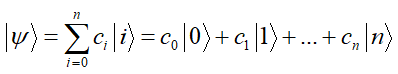

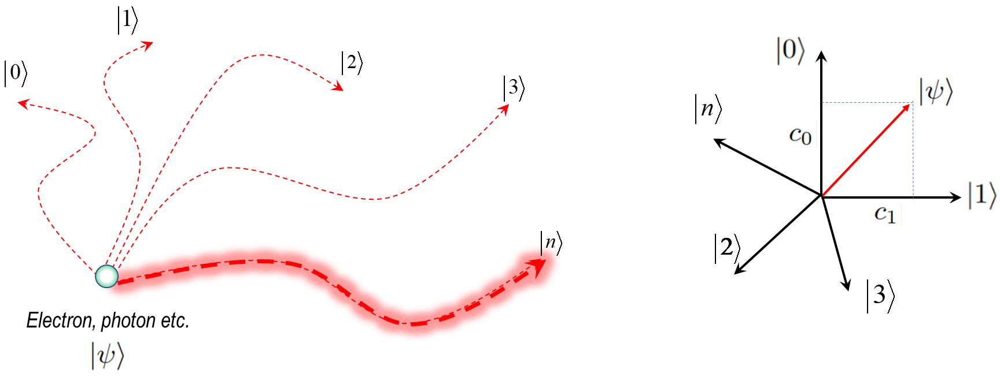

## A qubit

A qubit has two orthonormal basis states $|0\rangle$ and $|1\rangle$ and infinitely many pure states

$$|\psi\rangle=\alpha|0\rangle+\beta|1\rangle,
\qquad |\alpha|^2+|\beta|^2=1.$$

An overall phase $e^{i\gamma}$ does not change physical predictions; the relative amplitude and phase do.

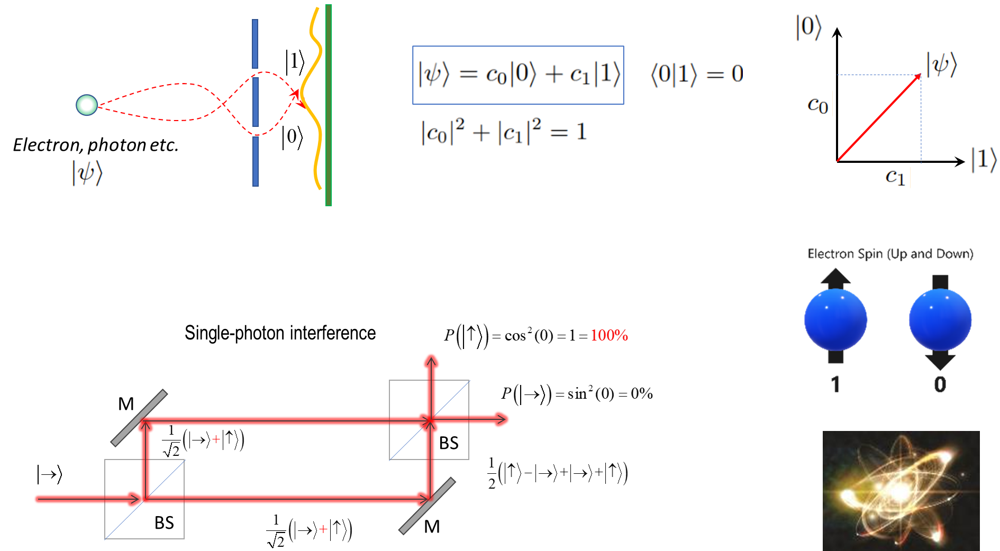

## Two qubits and entanglement

A general two-qubit pure state is

$$|\psi\rangle=\sum_{i,j=0}^{1}c_{ij}|ij\rangle,
\qquad \sum_{ij}|c_{ij}|^2=1.$$

It is a product state only when the coefficient matrix has rank one; for two qubits this is equivalent to $c_{00}c_{11}=c_{01}c_{10}$. The tensor-product equality in the figure applies only to separable states, not to an arbitrary two-qubit state.

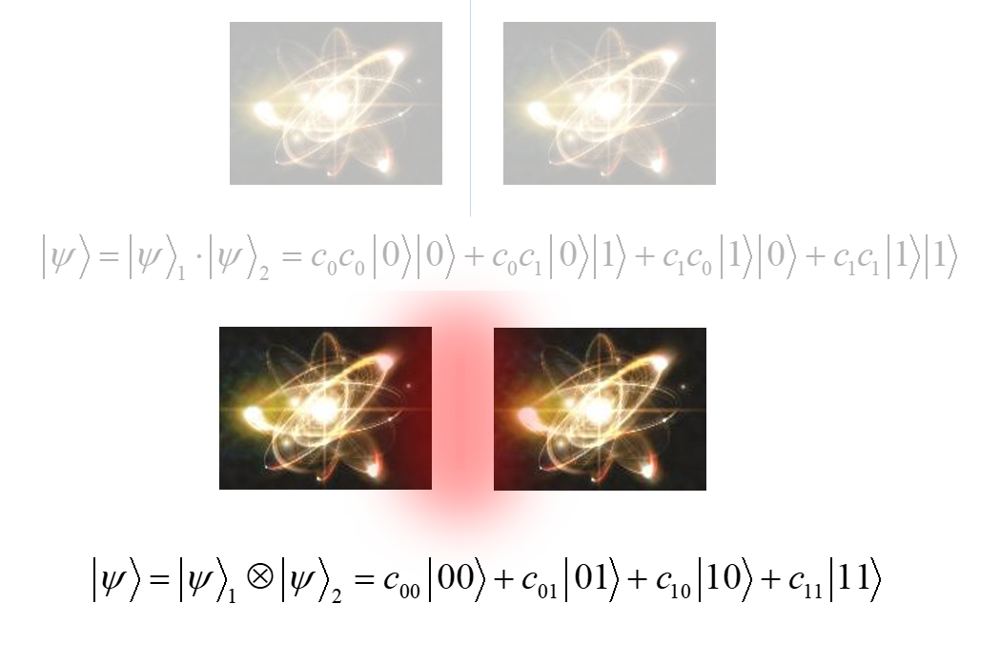

## Three qubits

A general three-qubit pure state is

$$|\psi\rangle=\sum_{i,j,k=0}^{1}c_{ijk}|ijk\rangle,
\qquad \sum_{ijk}|c_{ijk}|^2=1,$$

and need not factor into three one-qubit states. The tensor-product equality in the figure describes only fully separable states.

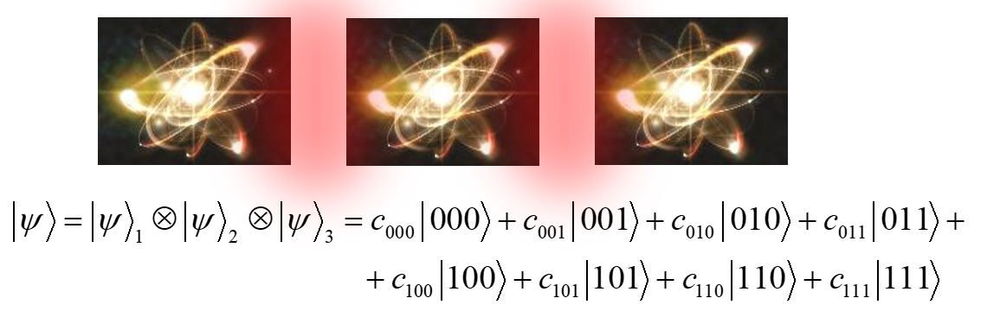

## Bell and GHZ states

For $N=2$,

$$|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt2$$

is a Bell state. For $N\ge3$,

$$|\mathrm{GHZ}_N\rangle=(|0\rangle^{\otimes N}+|1\rangle^{\otimes N})/\sqrt2$$

is a GHZ state. Measuring one qubit changes conditional correlations but cannot be used for faster-than-light signaling.

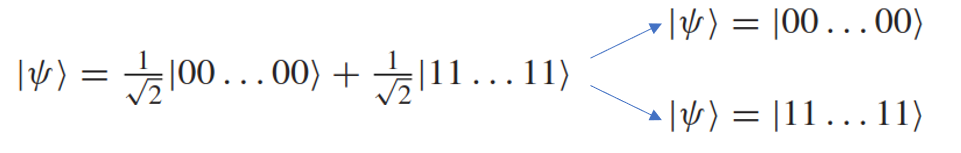

## State-space growth and “quantum parallelism”

A pure $N$-qubit state vector has $2^N$ complex amplitudes, not $2^N$ separate wavefunctions. The exponential representation does not expose all amplitudes as classical data: one computational-basis measurement returns one $N$-bit string. Advantage requires an algorithm that uses interference to concentrate useful information into measurable statistics.

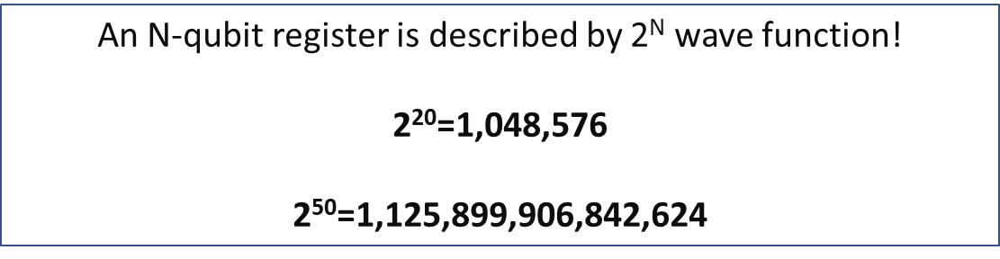

## Quantum interference

For amplitudes $a$ and $b$ leading to the same outcome, the probability contains a cross term:

$$|a+b|^2=|a|^2+|b|^2+2\operatorname{Re}(a^*b).$$

Quantum gates control relative phases so unwanted outcomes interfere destructively and useful outcomes constructively. Each shot still yields one $N$-bit result; repeated shots estimate the resulting distribution.

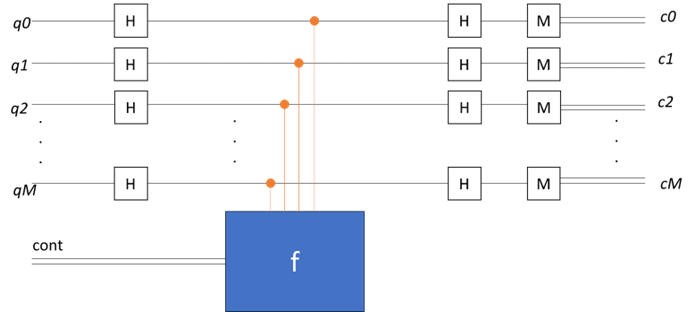

## Qubit modalities

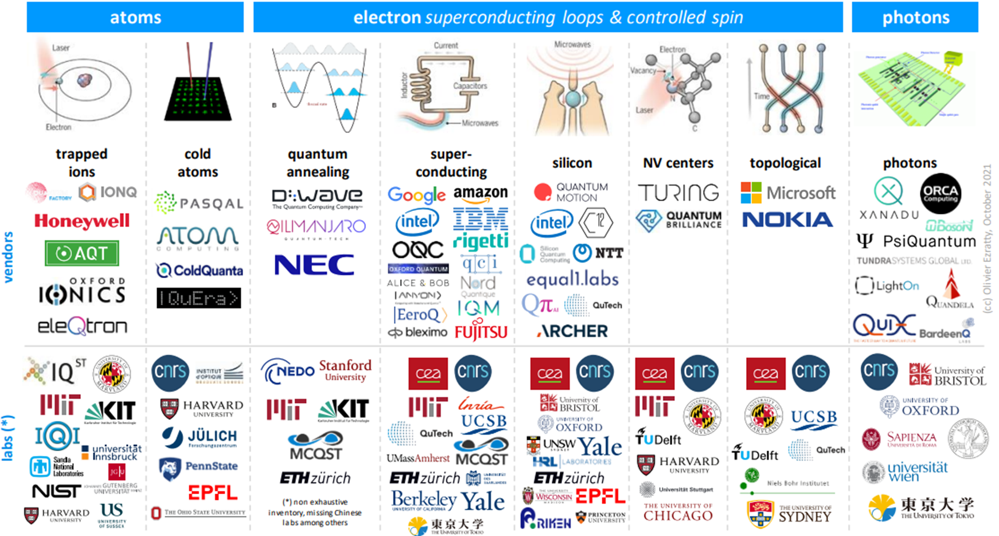

The logos are an incomplete snapshot and do not rank the organizations. Organizations, processor names, and device sizes change rapidly, so compare encodings and capabilities, as in the table of [Lecture 11](./11_quantum_computer_architectures.ipynb), and do not infer performance from the number of logos or from headline qubit counts.

## Why focus on superconducting circuits?

[Lecture 11](./11_quantum_computer_architectures.ipynb) compares superconducting, trapped-ion, neutral-atom, spin, and photonic platforms using common capability and resource criteria. This lecture narrows the engineering question: how do Josephson nonlinearity, microwave control, dispersive readout, cryogenics, fabrication, and error correction combine to make a superconducting processor?

Superconducting circuits offer fast gates, lithographic integration, and mature microwave instrumentation. Their central scaling constraints include materials and interface loss, leakage, crosstalk, fabrication spread, calibration drift, wiring density, and cryogenic heat load. These tradeoffs, more than the count of physical qubits, motivate the device and system models that follow. See [Krantz et al. (2019)](https://doi.org/10.1063/1.5089550).


## Microwaves in superconducting quantum computing

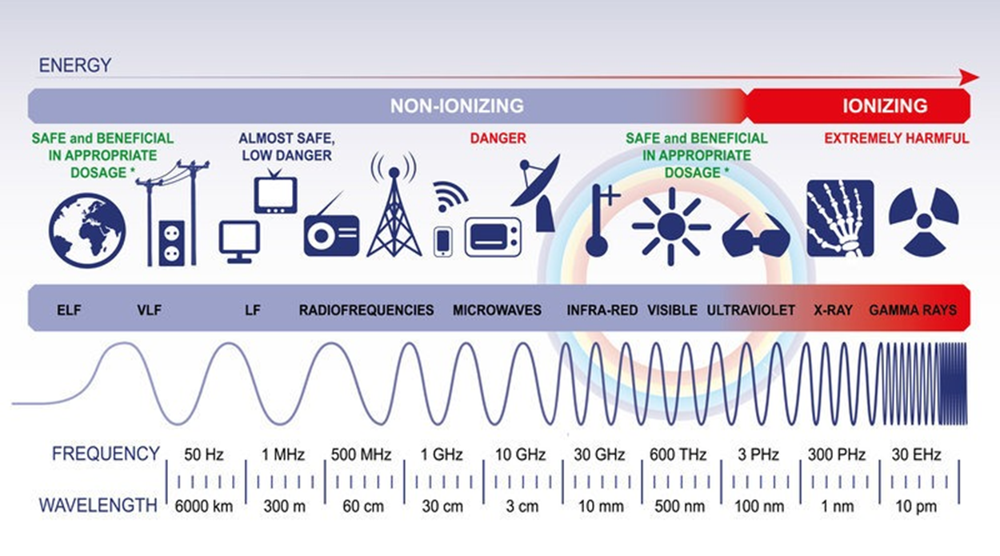

Microwave-frequency signals control and read out many superconducting circuits. The figure's simple “safe/dangerous” color labels are not a technical exposure assessment: risk depends on frequency, power, duration, geometry, and the applicable standard. In this lecture the spectrum serves only to locate typical control and readout frequencies.

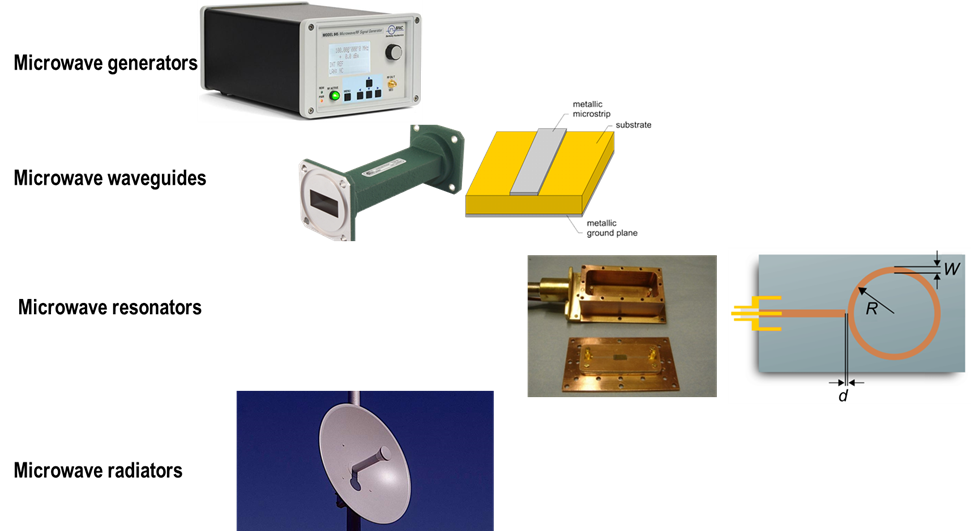

Arbitrary-waveform generators, mixers, filters, transmission lines, resonators, amplifiers, and antennas shape and route microwave signals subject to finite bandwidth, noise, dynamic range, power, and calibration limits. Josephson nonlinearity creates the transmon's anharmonic spectrum; linear resonators usually provide readout, buses, filters, or storage rather than the qubit nonlinearity itself.

Reference: Bardin, Slichter, and Reilly, [*IEEE J. Microwaves* **1**, 403–427 (2021)](https://doi.org/10.1109/JMW.2020.3034071).

## Why a bare linear resonator is not an addressable two-level qubit

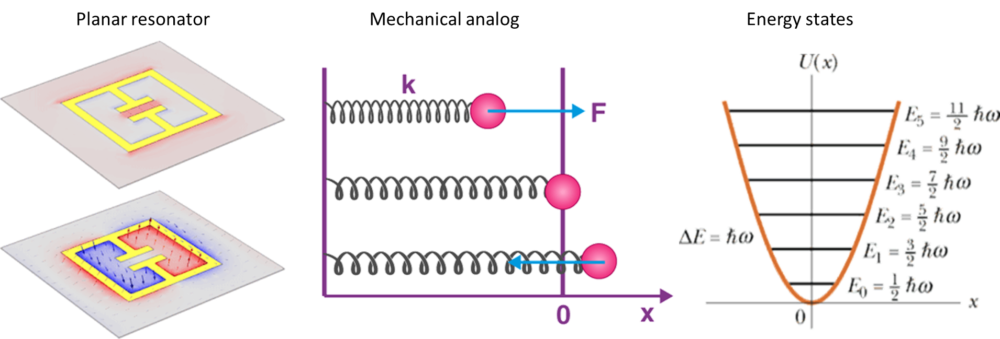

An ideal oscillator has

$$E_n=\hbar\omega\left(n+\frac12\right),$$

so every adjacent transition has frequency $\omega$. A resonant linear drive cannot selectively address only $|0\rangle\leftrightarrow|1\rangle$. Nevertheless, logical qubits can be encoded in oscillator states when ancillary nonlinearity, control, and error correction are supplied; “not a qubit” here refers to the bare linear mode used as a two-level device.

## Superconductivity and operating temperature

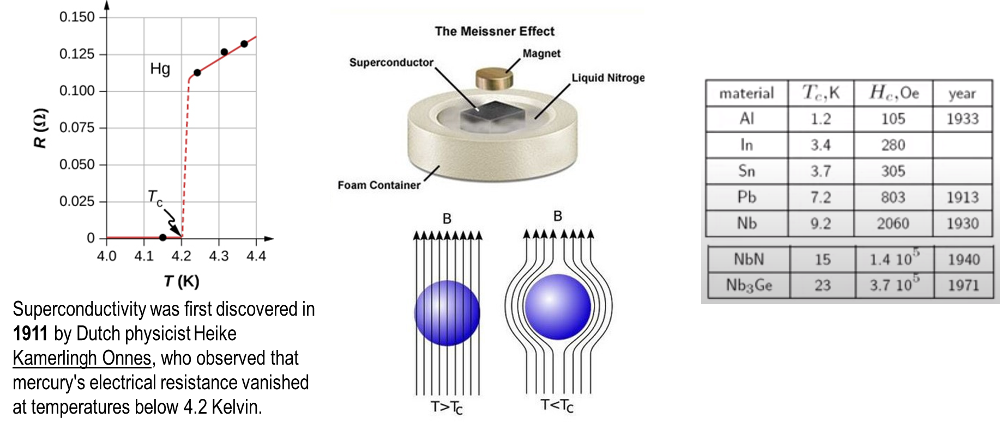

Below material- and field-dependent critical values, a superconductor supports dissipationless DC current and exhibits the Meissner response. Type-II superconductors can host magnetic vortices between their lower and upper critical fields, so “complete field expulsion” is not universal under all conditions.

Superconducting processors commonly operate near 10–20 mK, far below typical values of $T_c$, because being just below $T_c$ does not suppress thermal excitation, quasiparticles, or microwave loss at qubit frequencies well enough.

## Dilution refrigeration

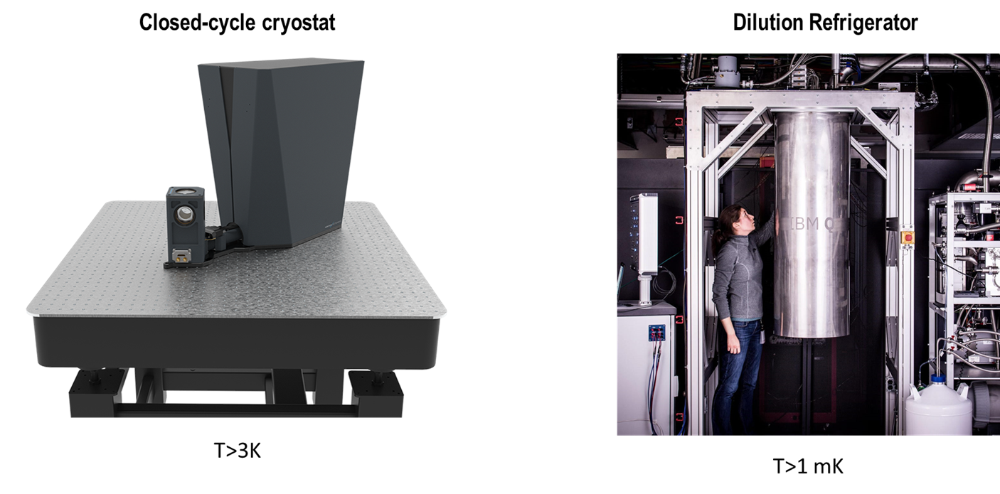

A pulse-tube (closed-cycle) cryocooler typically reaches a few kelvin; a dilution refrigerator adds still, cold-plate, and mixing-chamber stages to reach millikelvin temperatures. The inequalities printed in the figure should be read as approximate technology ranges, not lower-bound operating requirements. A qubit chip is commonly anchored near 10 mK, while attenuators, filters, isolators or circulators, and amplifiers are distributed across warmer stages to manage heat and thermal photons.

## Josephson nonlinearity

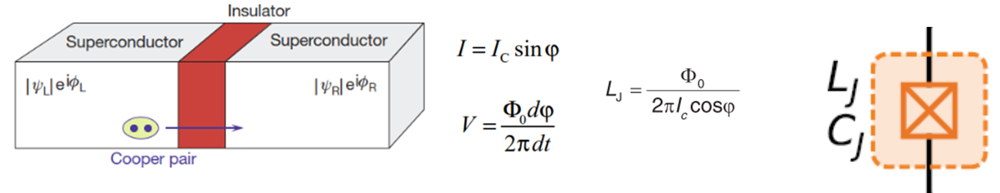

A Josephson junction consists of two superconductors separated by a weak link. An approximately 1 nm AlO$_x$ barrier is representative of Al/AlO$_x$/Al tunnel junctions, not every junction technology. The Josephson relations are

$$I=I_c\sin\phi,\qquad V=\frac{\Phi_0}{2\pi}\frac{d\phi}{dt},$$

and the small-signal inductance is $L_J(\phi)=\Phi_0/[2\pi I_c\cos\phi]$. For a Cooper-pair box or transmon,

$$H=4E_C(\hat n-n_g)^2-E_J\cos\hat\phi,$$

where the cosine supplies the nonlinearity needed for an anharmonic spectrum.

## Josephson-junction qubit: the transmon

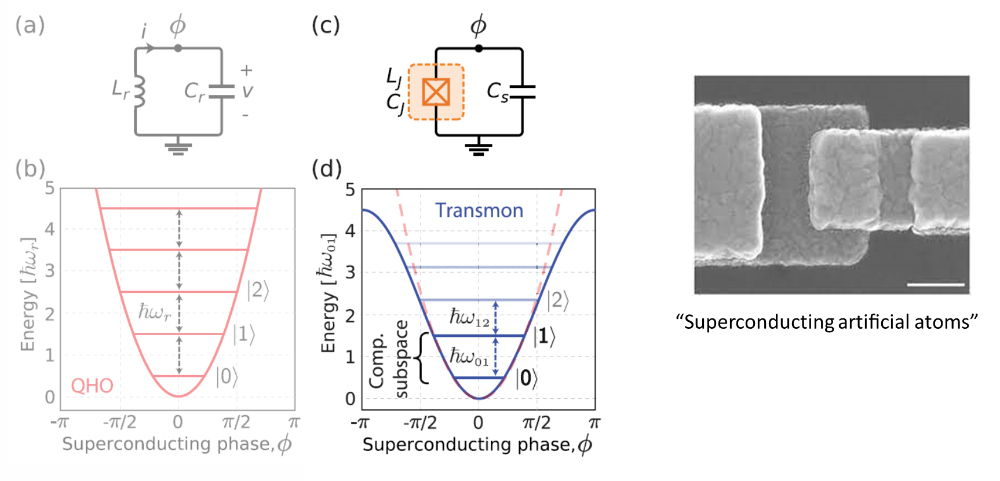

In the transmon regime $E_J/E_C\gg1$, charge dispersion is exponentially suppressed while finite anharmonicity keeps the $|0\rangle\leftrightarrow|1\rangle$ transition spectrally distinguishable from $|1\rangle\leftrightarrow|2\rangle$.

Reference: J. Koch *et al.*, [*Phys. Rev. A* **76**, 042319 (2007)](https://doi.org/10.1103/PhysRevA.76.042319).

## Approximate transmon spectrum

Expanding the cosine near a potential minimum gives a weakly anharmonic oscillator. To leading order,

$$
\hbar\omega_{01}\approx\sqrt{8E_JE_C}-E_C,
\qquad
\hbar\alpha\equiv\hbar(\omega_{12}-\omega_{01})\approx-E_C.
$$

Large $E_J/E_C$ suppresses sensitivity to offset charge, but it also reduces relative anharmonicity. A control pulse must therefore be spectrally narrow enough to avoid $|2\rangle$ while short enough compared with decoherence and drift. For a SQUID transmon, external flux changes the effective $E_J$ and tunes $\omega_{01}$, at the cost of flux-noise sensitivity away from a sweet spot.

Source: J. Koch *et al.*, [*Phys. Rev. A* **76**, 042319 (2007)](https://doi.org/10.1103/PhysRevA.76.042319).

## Microwave control and Rabi rotations

A near-resonant microwave pulse controls the rotation axis through its phase and the rotation angle through its calibrated pulse area. Ideal coherent Rabi oscillations are sinusoidal; relaxation, detuning, amplitude error, waveform distortion, and leakage reduce or distort them.

## Driven-control Hamiltonian and leakage

A capacitively coupled tone can be modeled as

$$
H_d/\hbar=\Omega_d(t)\cos(\omega_dt+\phi)(a+a^\dagger).
$$

After restricting to two levels and making a rotating-wave approximation, use the physics convention $\sigma_z=|e\rangle\!\langle e|-|g\rangle\!\langle g|$. A useful rotating-frame form is

$$
H_{\mathrm{rot}}/\hbar
=\frac{\Delta}{2}\sigma_z+\frac{\Omega_R(t)}{2}
\bigl(\cos\phi\,\sigma_x+\sin\phi\,\sigma_y\bigr),
$$

where $\Delta=\omega_q-\omega_d$. On resonance, the rotation angle is $\vartheta=\int\Omega_R(t)\,dt$. Amplitude, phase, detuning, waveform distortion, and mixer imperfections therefore map directly to coherent gate errors.

The transmon is not exactly two level. Fast pulses can populate $|2\rangle$; a DRAG (derivative removal by adiabatic gate) pulse adds a derivative-shaped quadrature that suppresses this leakage and the phase error that comes with it. See F. Motzoi *et al.*, [*Phys. Rev. Lett.* **103**, 110501 (2009)](https://doi.org/10.1103/PhysRevLett.103.110501).

## A transmon with dispersive readout and control

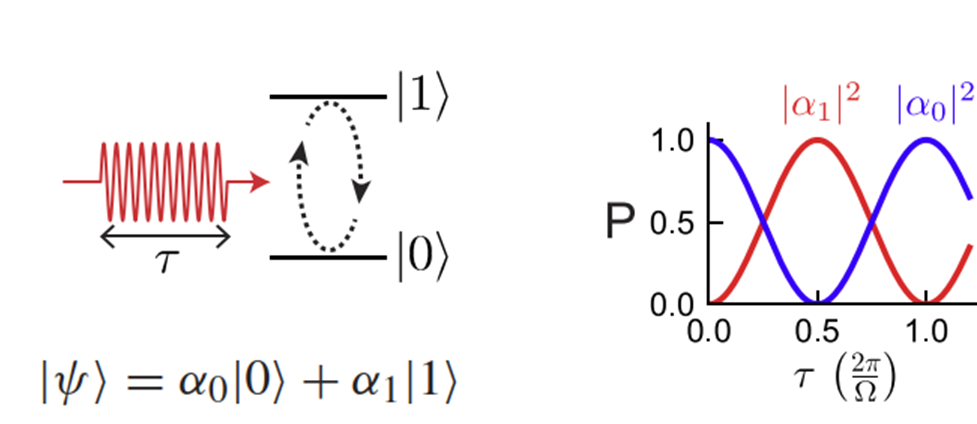

A linear resonator couples dispersively to the qubit for readout. In the illustrated schematic, $C_\kappa$ sets external coupling between the readout resonator and its feedline, while $C_g$ couples resonator and qubit. The XY drive uses a separate capacitive path, and a Z/flux line couples inductively to a flux-tunable SQUID loop. Symbols vary across schematics, so infer their roles from circuit connectivity rather than the letter alone.

## Dispersive readout from the Jaynes-Cummings model

Use the physics convention

$$\sigma_z=|e\rangle\!\langle e|-|g\rangle\!\langle g|,
\qquad \sigma_-=|g\rangle\!\langle e|.$$

Then the two-level Jaynes-Cummings Hamiltonian is

$$
H/\hbar=\omega_ra^\dagger a+\frac{\omega_q}{2}\sigma_z
+g(a^\dagger\sigma_-+a\sigma_+).
$$

This $\sigma_z$ is the negative of Qiskit's computational Pauli $Z=|0\rangle\!\langle0|-|1\rangle\!\langle1|$ when $|g\rangle=|0\rangle$ and $|e\rangle=|1\rangle$. Keeping the symbols distinct prevents an accidental energy-level reversal.

With $\Delta=\omega_q-\omega_r$ and $|g/\Delta|\ll1$, a perturbative transformation gives

$$
H_{\mathrm{disp}}/\hbar\approx
(\omega_r+\chi\sigma_z)a^\dagger a
+\frac{\omega_q+\chi}{2}\sigma_z,
\qquad \chi\approx\frac{g^2}{\Delta}
$$

for an ideal two-level system in this convention. For a transmon with anharmonicity $\alpha$, a common approximation is $\chi\approx g^2\alpha/[\Delta(\Delta+\alpha)]$; authors may absorb a sign into $\chi$ or $\sigma_z$, so compare conventions before using a formula. The two qubit states shift the resonator frequency by $2|\chi|$.

The dispersive approximation weakens as photon number approaches $n_{\mathrm{crit}}\approx\Delta^2/(4g^2)$. Readout power, integration time, amplifier efficiency, measurement-induced dephasing, Purcell decay, and assignment error form a coupled design budget.

Reference: A. Blais *et al.*, [*Rev. Mod. Phys.* **93**, 025005 (2021)](https://doi.org/10.1103/RevModPhys.93.025005).

## Relaxation and dephasing

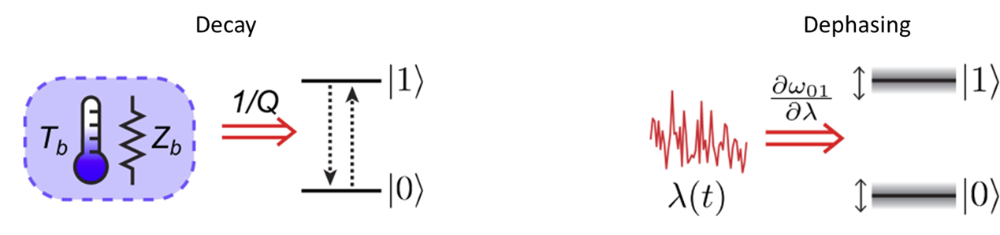

$T_1$ characterizes energy relaxation. Pure dephasing is described by $T_\phi$; Ramsey and echo experiments estimate different transverse coherence times because echo suppresses some low-frequency noise. In a stationary Markovian model,

$$\frac1{T_2}=\frac1{2T_1}+\frac1{T_\phi},$$

which implies $T_2\le2T_1$. Non-Markovian drift, pulse errors, leakage, readout error, and correlated noise require additional characterization; one coherence number is not a complete error budget.

## A minimal Josephson-junction circuit

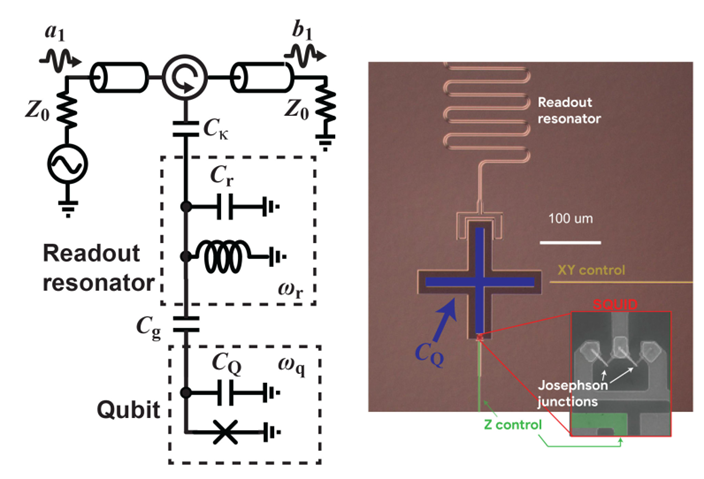

The junction supplies nonlinear inductance while shunt capacitance sets charging energy. Circuit quantization, rather than the schematic alone, determines the mode frequency, anharmonicity, charge or flux sensitivity, and coupling to control and readout ports.

## Cryogenic system stack

Input lines are progressively attenuated and filtered to thermalize noise. Output signals pass through nonreciprocal components and a near-quantum-limited amplifier before warmer gain stages. Every cable adds conductive heat load, so packaging, multiplexing, shielding, and cryogenic control electronics become architectural constraints as channel count grows.

## Coupling and entangling operations I

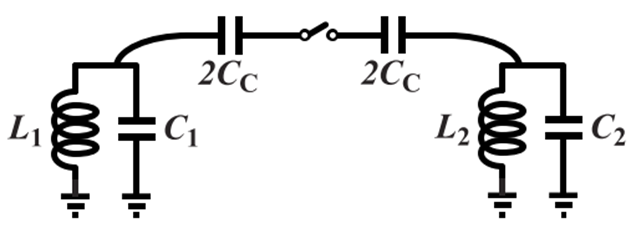

A switchable or parametrically activated interaction can mediate a two-qubit gate. Coupling enables entanglement for suitable initial states and pulse sequences; coupling by itself does not imply that the quantum state is entangled. An ideal switch is a circuit abstraction, not a literal lossless microwave switch at the qubit node.

## Coupling and entangling operations II

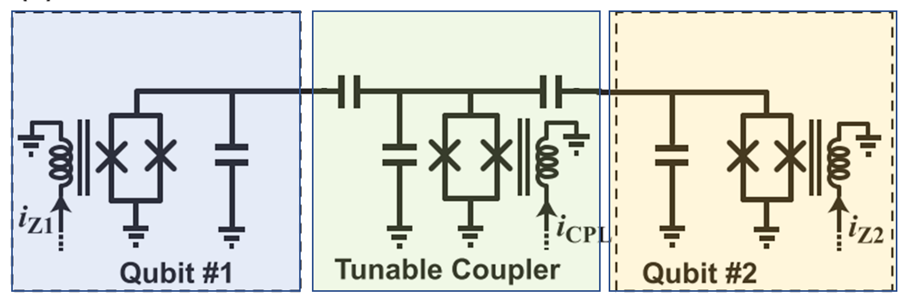

A tunable coupler is an additional nonlinear circuit used to control effective qubit–qubit interactions, suppress idle coupling, and implement entangling gates. Its benefits must be balanced against extra modes, control lines, calibration, leakage, and coupler-induced decoherence.

Reference: Y. Sung *et al.*, [*Phys. Rev. X* **11**, 021058 (2021)](https://doi.org/10.1103/PhysRevX.11.021058).

## Single- and two-qubit gates

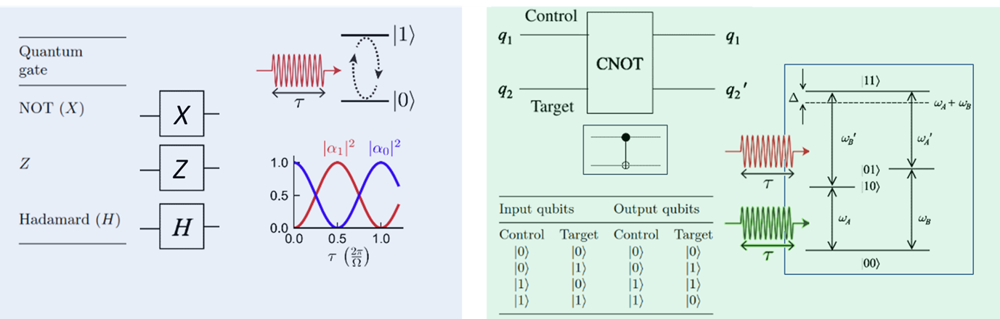

Single-qubit gates are calibrated microwave rotations. Two-qubit gates arise from engineered interactions: exchange terms produce iSWAP-family gates, conditional $ZZ$ evolution produces controlled phases, and microwave-driven effective interactions can produce cross-resonance $ZX$ gates. The level diagram is illustrative; a real implementation must specify pulse shape, interaction Hamiltonian, local phase corrections, leakage, and calibration.

## Effective two-qubit interactions

Different pulse and coupler designs realize different effective Hamiltonians:

- Exchange coupling, $H_{\mathrm{ex}}/\hbar=J(\sigma_+^{(1)}\sigma_-^{(2)}+\mathrm{h.c.})$, produces iSWAP-family evolution.
- A conditional term $H_{ZZ}/\hbar=(\zeta/4)Z\otimes Z$ accumulates a controlled phase after local phase corrections.
- Cross-resonance driving produces a dominant effective $ZX$ interaction together with unwanted single- and two-qubit terms that must be echoed or calibrated.

Gate fidelity depends on pulse bandwidth, detuning, residual coupling, spectator qubits, leakage, and calibration stability. A circuit symbol such as CNOT specifies the logical unitary, not one universal physical pulse sequence.

Primary examples: J. M. Chow *et al.*, [*Phys. Rev. Lett.* **107**, 080502 (2011)](https://doi.org/10.1103/PhysRevLett.107.080502); Y. Sung *et al.*, [*Phys. Rev. X* **11**, 021058 (2021)](https://doi.org/10.1103/PhysRevX.11.021058).

## What has improved and what remains

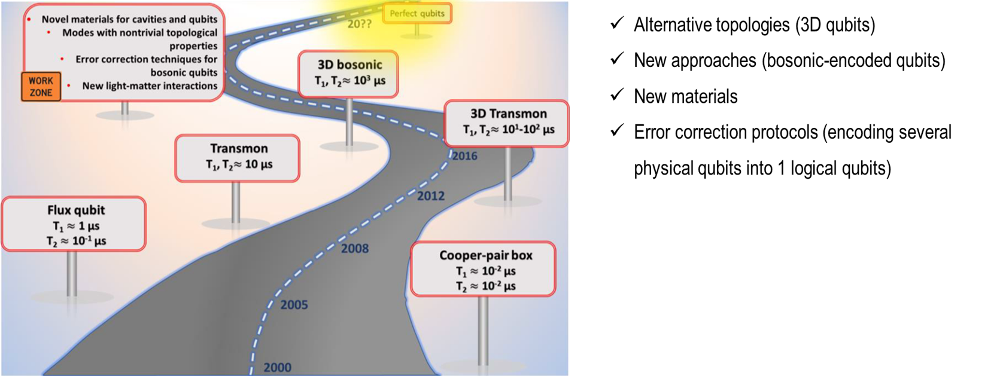

Progress includes lower-loss materials, improved fabrication, tunable couplers, multiplexed readout, three-dimensional integration and packaging, better calibration, and demonstrations of logical-error suppression below threshold. Remaining work includes leakage control, long-term stability, correlated-error diagnosis, cryogenic I/O, fast decoding, and reducing physical-resource overhead per useful logical qubit.

Selected evidence: [tantalum transmons](https://doi.org/10.1038/s41467-021-22030-5), [millisecond fluxonium](https://doi.org/10.1103/PhysRevLett.130.267001), and [surface-code scaling](https://doi.org/10.1038/s41586-024-08449-y) with its [2026 author correction](https://doi.org/10.1038/s41586-026-10559-8). The figure is associated with A. Krasnok *et al.*, [*Applied Physics Reviews* **11**, 011302 (2024)](https://doi.org/10.1063/5.0155213).

## Error budgets and logical qubits

Average gate infidelity alone does not make an error budget. A system-level error budget should include:

- relaxation and dephasing during gates, idles, measurement, and reset;
- coherent over/under-rotation, detuning, waveform distortion, and calibration drift;
- leakage outside the computational subspace and its lifetime;
- readout assignment, reset, crosstalk, spectator, and correlated errors; and
- duty cycle, decoder latency, and rare events over the full experiment duration.

For a distance-$d$ surface code under a simplified below-threshold noise model,

$$p_L(d)\approx A\left(\frac{p}{p_{\mathrm{th}}}\right)^{(d+1)/2}.$$

This empirical scaling is code-, circuit-, decoder-, and noise-model dependent. A logical memory below threshold is a decisive milestone, but useful fault-tolerant computation also needs logical state preparation, gates, measurement, routing, non-Clifford resources, and a total algorithm failure budget. If $L$ logical locations each fail independently with small probability $p_L$, the rough estimate $P_{\mathrm{fail}}\approx Lp_L$ illustrates why long algorithms demand logical errors far below component-level percentages.

Sources: A. G. Fowler *et al.*, [*Phys. Rev. A* **86**, 032324 (2012)](https://doi.org/10.1103/PhysRevA.86.032324); Google Quantum AI and Collaborators, [*Nature* **638**, 920–926 (2025)](https://doi.org/10.1038/s41586-024-08449-y), with [2026 author correction](https://doi.org/10.1038/s41586-026-10559-8).

## Full-stack superconducting system

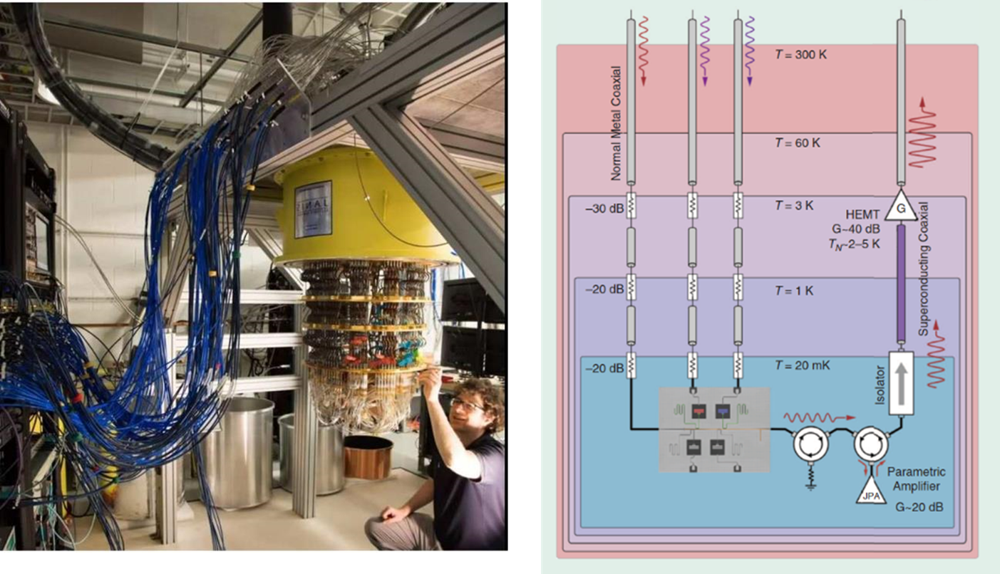

*The left panel shows a cryogenic superconducting processor installation; the right panel traces control and readout signals through attenuators, filters, amplifiers, and temperature stages from room temperature to the millikelvin device.*


## Quantum workforce resources

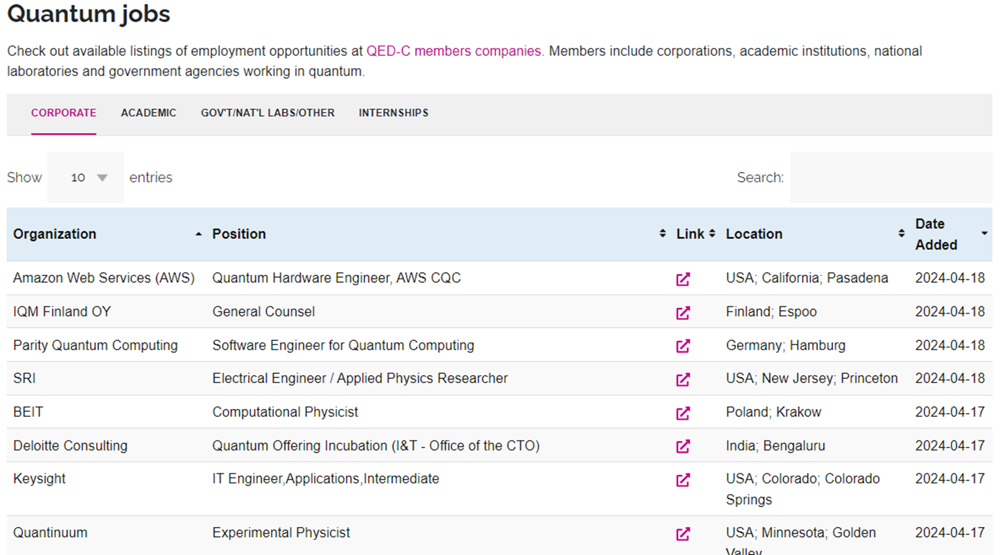

Job boards are time dependent. The [QED-C Quantum Jobs page](https://quantumconsortium.org/quantum-jobs/) provides current listings; the image records examples visible in 2024.

## Key takeaways

- The transmon balances reduced charge sensitivity against finite anharmonicity by operating at large $E_J/E_C$.
- Microwave drives implement calibrated rotations, engineered interactions implement two-qubit gates, and dispersive shifts enable readout.
- Relaxation, dephasing, leakage, measurement error, crosstalk, and drift must be budgeted across gates, idles, reset, and readout.
- Scalable superconducting computing is a full-stack problem spanning materials, circuits, cryogenics, control, decoding, and fault-tolerant resources.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. J. C. Bardin *et al.*, [“Quantum computing: An introduction for microwave engineers”](https://doi.org/10.1109/MMM.2020.2993475), *IEEE Microwave Magazine* **21**, 24–44 (2020).
2. S. E. Rasmussen *et al.*, [“Superconducting circuit companion”](https://doi.org/10.1103/PRXQuantum.2.040204), *PRX Quantum* **2**, 040204 (2021).
3. S. Kwon *et al.*, [“Gate-based superconducting quantum computing”](https://doi.org/10.1063/5.0029735), *J. Appl. Phys.* **129**, 041102 (2021).
4. P. Krantz *et al.*, [“A quantum engineer's guide to superconducting qubits”](https://doi.org/10.1063/1.5089550), *Appl. Phys. Rev.* **6**, 021318 (2019).
5. A. Blais *et al.*, [“Circuit quantum electrodynamics”](https://doi.org/10.1103/RevModPhys.93.025005), *Rev. Mod. Phys.* **93**, 025005 (2021).
6. A. Krasnok *et al.*, [“Superconducting microwave cavities and qubits for quantum information systems”](https://doi.org/10.1063/5.0155213), *Appl. Phys. Rev.* **11**, 011302 (2024).
7. J. Koch *et al.*, [transmon theory](https://doi.org/10.1103/PhysRevA.76.042319), *Phys. Rev. A* **76**, 042319 (2007).
8. F. Motzoi *et al.*, [DRAG leakage control](https://doi.org/10.1103/PhysRevLett.103.110501), *Phys. Rev. Lett.* **103**, 110501 (2009).
9. J. M. Chow *et al.*, [cross-resonance gate](https://doi.org/10.1103/PhysRevLett.107.080502), *Phys. Rev. Lett.* **107**, 080502 (2011).
10. A. G. Fowler *et al.*, [surface-code error correction](https://doi.org/10.1103/PhysRevA.86.032324), *Phys. Rev. A* **86**, 032324 (2012).
11. Google Quantum AI and Collaborators, [below-threshold surface-code memories](https://doi.org/10.1038/s41586-024-08449-y), *Nature* **638**, 920–926 (2025), with [2026 author correction](https://doi.org/10.1038/s41586-026-10559-8).